In [ ]:
# ============================================================
# NewsGroupsTopicEval
# Notebook NG02 : Data Preprocessing & Cross Validation
#
# Purpose:
#   1. Load 20 Newsgroups dataset using scikit-learn API
#   2. Clean text
#   3. Tokenize
#   4. Encode labels
#   5. Create Stratified 5-Fold splits
#   6. Save folds for later notebooks
#
# NOTE:
# No LDA model is trained here.
# No Dictionary is built here.
# Dictionary construction belongs to Notebook 03
# to avoid data leakage.
# ============================================================

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# Imports
# ============================================================

import os
import re
import json
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.datasets import fetch_20newsgroups

from sklearn.model_selection import StratifiedKFold

from sklearn.preprocessing import LabelEncoder


import nltk

from nltk.tokenize import word_tokenize

from nltk.corpus import stopwords

from nltk.stem import WordNetLemmatizer


warnings.filterwarnings("ignore")

In [ ]:
# ============================================================
# Load Configuration
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval"
)


CONFIG_FILE = (
    PROJECT_ROOT
    / "config"
    / "config.json"
)


with open(CONFIG_FILE) as f:

    CONFIG = json.load(f)


SEED = CONFIG["random_seed"]


DATA_DIR = (
    PROJECT_ROOT
    / "data"
)


FOLD_DIR = (
    PROJECT_ROOT
    / "folds"
)


print("Configuration Loaded")

print()

print("Project Root :", PROJECT_ROOT)

print("Data Directory :", DATA_DIR)

print("Fold Directory :", FOLD_DIR)

print("Random Seed :", SEED)

Configuration Loaded

Project Root : /content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval
Data Directory : /content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/data
Fold Directory : /content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/folds
Random Seed : 42


In [ ]:
# ============================================================
# Reproducibility
# ============================================================

random.seed(SEED)

np.random.seed(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)


print(
    "Random Seed Set:",
    SEED
)

Random Seed Set: 42


In [ ]:
# ============================================================
# Download 20 Newsgroups Dataset
# ============================================================

newsgroups = fetch_20newsgroups(

    subset="all",

    remove=(
        "headers",
        "footers",
        "quotes"
    ),

    shuffle=True,

    random_state=SEED
)


print(
    "20 Newsgroups Dataset Downloaded Successfully"
)


print()

print(
    "Total Documents:",
    len(newsgroups.data)
)


print(
    "Total Classes:",
    len(newsgroups.target_names)
)

20 Newsgroups Dataset Downloaded Successfully

Total Documents: 18846
Total Classes: 20


In [ ]:
# ============================================================
# Create Standardized Dataset
# ============================================================

df = pd.DataFrame({

    "DocumentID":
        np.arange(
            len(newsgroups.data)
        ),

    "Text":
        newsgroups.data,

    "Label":
        newsgroups.target
})


df["Category"] = [

    newsgroups.target_names[label]

    for label in df["Label"]
]


print(df.shape)


df.head()

(18846, 4)


,DocumentID,Text,Label,Category
0,0,\n\nI am sure some bashers of Pens fans are pr...,10,rec.sport.hockey
1,1,My brother is in the market for a high-perform...,3,comp.sys.ibm.pc.hardware
2,2,\n\n\n\n\tFinally you said what you dream abou...,17,talk.politics.mideast
3,3,\nThink!\n\nIt's the SCSI card doing the DMA t...,3,comp.sys.ibm.pc.hardware
4,4,1) I have an old Jasmine drive which I cann...,4,comp.sys.mac.hardware


In [ ]:
# ============================================================
# Dataset Inspection
# ============================================================

print("=" * 70)

print("DATASET INFORMATION")

print("=" * 70)


print()

print(
    "Documents:",
    len(df)
)


print(
    "Classes:",
    df["Label"].nunique()
)


print(
    "Missing Text:",
    df["Text"].isna().sum()
)


print(
    "Duplicate Documents:",
    df["Text"].duplicated().sum()
)


print()

print(
    "Documents per Category"
)


print(

    df["Category"]
    .value_counts()
    .sort_index()
)

DATASET INFORMATION

Documents: 18846
Classes: 20
Missing Text: 0
Duplicate Documents: 559

Documents per Category
Category
alt.atheism                 799
comp.graphics               973
comp.os.ms-windows.misc     985
comp.sys.ibm.pc.hardware    982
comp.sys.mac.hardware       963
comp.windows.x              988
misc.forsale                975
rec.autos                   990
rec.motorcycles             996
rec.sport.baseball          994
rec.sport.hockey            999
sci.crypt                   991
sci.electronics             984
sci.med                     990
sci.space                   987
soc.religion.christian      997
talk.politics.guns          910
talk.politics.mideast       940
talk.politics.misc          775
talk.religion.misc          628
Name: count, dtype: int64


In [ ]:
# ============================================================
# Remove Missing Documents
# ============================================================

initial_documents = len(df)


df = df.dropna(

    subset=["Text"]
)


df["Text"] = (

    df["Text"]
    .astype(str)
)


df = df[

    df["Text"]
    .str.strip()
    != ""
]


df = df.reset_index(

    drop=True
)


print(
    "Initial Documents:",
    initial_documents
)


print(
    "Final Documents:",
    len(df)
)


print(
    "Removed Documents:",
    initial_documents - len(df)
)

Initial Documents: 18846
Final Documents: 18331
Removed Documents: 515


In [ ]:
# ============================================================
# Download NLTK Resources
# ============================================================

nltk.download(
    "punkt"
)

nltk.download(
    "punkt_tab"
)

nltk.download(
    "stopwords"
)

nltk.download(
    "wordnet"
)

nltk.download(
    "omw-1.4"
)


print(
    "NLTK Resources Ready"
)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLTK Resources Ready


In [ ]:
# ============================================================
# Initialize NLP Components
# ============================================================

STOP_WORDS = set(

    stopwords.words(
        "english"
    )
)


LEMMATIZER = (

    WordNetLemmatizer()
)


print(
    "Stopwords:",
    len(STOP_WORDS)
)


print(
    "Lemmatizer Initialized"
)

Stopwords: 198
Lemmatizer Initialized


In [ ]:
# ============================================================
# Text Cleaning Function
# ============================================================

def preprocess_text(text):


    # --------------------------------------------------------
    # Convert to lowercase
    # --------------------------------------------------------

    text = text.lower()


    # --------------------------------------------------------
    # Remove URLs
    # --------------------------------------------------------

    text = re.sub(

        r"http\S+|www\S+",

        " ",

        text
    )


    # --------------------------------------------------------
    # Remove email addresses
    # --------------------------------------------------------

    text = re.sub(

        r"\S+@\S+",

        " ",

        text
    )


    # --------------------------------------------------------
    # Keep alphabetic characters
    # --------------------------------------------------------

    text = re.sub(

        r"[^a-zA-Z\s]",

        " ",

        text
    )


    # --------------------------------------------------------
    # Tokenization
    # --------------------------------------------------------

    tokens = word_tokenize(

        text
    )


    # --------------------------------------------------------
    # Remove stopwords
    # --------------------------------------------------------

    tokens = [

        token

        for token in tokens

        if token not in STOP_WORDS
    ]


    # --------------------------------------------------------
    # Keep alphabetic tokens
    # --------------------------------------------------------

    tokens = [

        token

        for token in tokens

        if token.isalpha()
    ]


    # --------------------------------------------------------
    # Lemmatization
    # --------------------------------------------------------

    tokens = [

        LEMMATIZER.lemmatize(
            token
        )

        for token in tokens
    ]


    return tokens

In [ ]:
# ============================================================
# Apply Text Preprocessing
# ============================================================

print(
    "Preprocessing Documents..."
)


df["Tokens"] = (

    df["Text"]
    .apply(
        preprocess_text
    )
)


print(
    "Text Preprocessing Completed"
)

Preprocessing Documents...
Text Preprocessing Completed


In [ ]:
# ============================================================
# Remove Empty Tokenized Documents
# ============================================================

before_filtering = len(df)


df = df[

    df["Tokens"]
    .apply(len)
    > 0
]


df = df.reset_index(

    drop=True
)


print(
    "Documents Before Filtering:",
    before_filtering
)


print(
    "Documents After Filtering:",
    len(df)
)


print(
    "Removed Empty Documents:",
    before_filtering - len(df)
)

Documents Before Filtering: 18331
Documents After Filtering: 18297
Removed Empty Documents: 34


In [ ]:
# ============================================================
# Encode Labels
# ============================================================

label_encoder = LabelEncoder()


df["LabelID"] = (

    label_encoder.fit_transform(

        df["Category"]
    )
)


print(
    "Label Encoding Completed"
)


print()

print(

    df[
        [
            "LabelID",
            "Category"
        ]
    ]

    .drop_duplicates()

    .sort_values(
        "LabelID"
    )
)

Label Encoding Completed

    LabelID                  Category
14        0               alt.atheism
22        1             comp.graphics
46        2   comp.os.ms-windows.misc
1         3  comp.sys.ibm.pc.hardware
4         4     comp.sys.mac.hardware
21        5            comp.windows.x
28        6              misc.forsale
20        7                 rec.autos
19        8           rec.motorcycles
33        9        rec.sport.baseball
0        10          rec.sport.hockey
11       11                 sci.crypt
5        12           sci.electronics
13       13                   sci.med
25       14                 sci.space
78       15    soc.religion.christian
26       16        talk.politics.guns
2        17     talk.politics.mideast
37       18        talk.politics.misc
9        19        talk.religion.misc


In [ ]:
# ============================================================
# Dataset Statistics
# ============================================================

df["DocumentLength"] = (

    df["Tokens"]
    .apply(len)
)


print("=" * 60)

print("DATASET STATISTICS")

print("=" * 60)


print(
    "Documents :",
    len(df)
)


print(
    "Average Length :",
    df["DocumentLength"].mean()
)


print(
    "Median Length :",
    df["DocumentLength"].median()
)


print(
    "Maximum Length :",
    df["DocumentLength"].max()
)


print(
    "Minimum Length :",
    df["DocumentLength"].min()
)


print("=" * 60)


VOCABULARY = set(

    token

    for document in df["Tokens"]

    for token in document
)


print(
    "Vocabulary Size :",
    len(VOCABULARY)
)

DATASET STATISTICS
Documents : 18297
Average Length : 106.89495545717877
Median Length : 44.0
Maximum Length : 15388
Minimum Length : 1
Vocabulary Size : 78235


Category
alt.atheism                 779
comp.graphics               953
comp.os.ms-windows.misc     946
comp.sys.ibm.pc.hardware    963
comp.sys.mac.hardware       927
comp.windows.x              980
misc.forsale                959
rec.autos                   934
rec.motorcycles             968
rec.sport.baseball          951
rec.sport.hockey            972
sci.crypt                   961
sci.electronics             956
sci.med                     960
sci.space                   954
soc.religion.christian      974
talk.politics.guns          885
talk.politics.mideast       917
talk.politics.misc          754
talk.religion.misc          604
Name: count, dtype: int64


<Axes: xlabel='Category'>

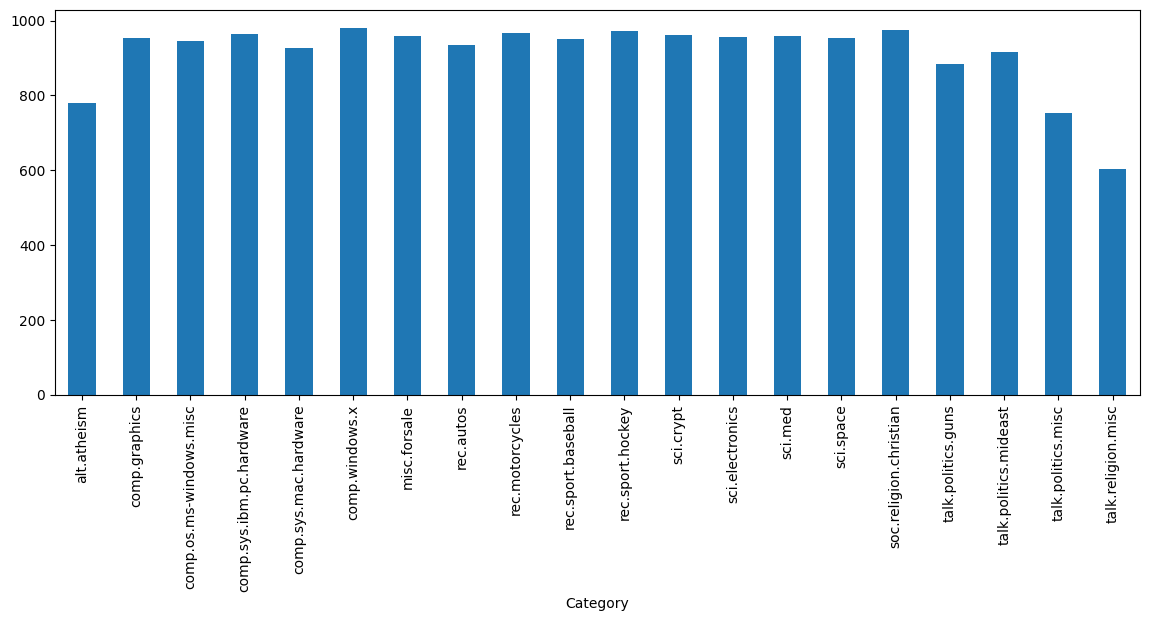

In [ ]:
# ============================================================
# Class Distribution
# ============================================================

distribution = (

    df["Category"]
    .value_counts()
    .sort_index()
)


print(
    distribution
)


distribution.plot.bar(

    figsize=(14, 5)
)

In [ ]:
# ============================================================
# NG02-18 — Create Stratified 5-Fold Splits
# Corrected for Excel Illegal Characters
# ============================================================

from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE


def clean_for_excel(value):
    """
    Remove characters that are illegal in Excel worksheets.
    """

    if isinstance(value, str):

        return ILLEGAL_CHARACTERS_RE.sub(
            "",
            value
        )

    return value


skf = StratifiedKFold(

    n_splits=CONFIG["n_folds"],

    shuffle=True,

    random_state=SEED
)


for fold, (

    train_index,
    test_index

) in enumerate(

    skf.split(

        df,

        df["LabelID"]
    ),

    1
):


    # --------------------------------------------------------
    # Create Train and Test DataFrames
    # --------------------------------------------------------

    train_df = (

        df
        .iloc[train_index]
        .copy()
        .reset_index(drop=True)
    )


    test_df = (

        df
        .iloc[test_index]
        .copy()
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Remove illegal Excel characters
    # --------------------------------------------------------

    for column in ["Text", "Category"]:

        if column in train_df.columns:

            train_df[column] = (

                train_df[column]
                .apply(clean_for_excel)
            )


        if column in test_df.columns:

            test_df[column] = (

                test_df[column]
                .apply(clean_for_excel)
            )


    # --------------------------------------------------------
    # Create Fold Directory
    # --------------------------------------------------------

    fold_path = (

        FOLD_DIR
        / f"Fold_{fold}"
    )


    fold_path.mkdir(

        parents=True,

        exist_ok=True
    )


    # --------------------------------------------------------
    # Save Train Data
    # --------------------------------------------------------

    train_df.to_excel(

        fold_path
        / "train.xlsx",

        index=False
    )


    # --------------------------------------------------------
    # Save Test Data
    # --------------------------------------------------------

    test_df.to_excel(

        fold_path
        / "test.xlsx",

        index=False
    )


    print(

        f"✓ Fold {fold} Saved"

    )


print()

print(

    "✓ All Stratified Folds Saved Successfully"

)

✓ Fold 1 Saved
✓ Fold 2 Saved
✓ Fold 3 Saved
✓ Fold 4 Saved
✓ Fold 5 Saved

✓ All Stratified Folds Saved Successfully


In [ ]:
# ============================================================
# Verify Fold Class Distribution
# ============================================================

for fold in range(

    1,

    CONFIG["n_folds"] + 1
):


    print(
        "=" * 50
    )


    print(
        f"Fold {fold}"
    )


    train = pd.read_excel(

        FOLD_DIR
        / f"Fold_{fold}"
        / "train.xlsx"
    )


    print(

        train["Category"]
        .value_counts()
        .sort_index()
    )


    print()

Fold 1
Category
alt.atheism                 623
comp.graphics               763
comp.os.ms-windows.misc     757
comp.sys.ibm.pc.hardware    771
comp.sys.mac.hardware       742
comp.windows.x              784
misc.forsale                767
rec.autos                   747
rec.motorcycles             774
rec.sport.baseball          761
rec.sport.hockey            777
sci.crypt                   769
sci.electronics             765
sci.med                     768
sci.space                   763
soc.religion.christian      779
talk.politics.guns          708
talk.politics.mideast       733
talk.politics.misc          603
talk.religion.misc          483
Name: count, dtype: int64

Fold 2
Category
alt.atheism                 623
comp.graphics               762
comp.os.ms-windows.misc     757
comp.sys.ibm.pc.hardware    771
comp.sys.mac.hardware       742
comp.windows.x              784
misc.forsale                767
rec.autos                   748
rec.motorcycles             774
rec.sport.bas

In [ ]:
# ============================================================
# Save Processed Dataset
# ============================================================

PROCESSED_DATASET_FILE = (

    DATA_DIR
    / "ProcessedDataset.pkl"
)


df.to_pickle(

    PROCESSED_DATASET_FILE
)


print(
    "Processed Dataset Saved"
)


print(
    PROCESSED_DATASET_FILE
)

Processed Dataset Saved
/content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/data/ProcessedDataset.pkl


In [ ]:
# ============================================================
# Save Label Mapping
# ============================================================

label_mapping = pd.DataFrame({

    "LabelID":
        range(
            len(
                label_encoder.classes_
            )
        ),

    "Category":
        label_encoder.classes_
})


LABEL_MAPPING_FILE = (

    DATA_DIR
    / "LabelMapping.csv"
)


label_mapping.to_csv(

    LABEL_MAPPING_FILE,

    index=False
)


print(
    "Label Mapping Saved"
)


display(
    label_mapping
)

Label Mapping Saved


,LabelID,Category
0,0,alt.atheism
1,1,comp.graphics
2,2,comp.os.ms-windows.misc
3,3,comp.sys.ibm.pc.hardware
4,4,comp.sys.mac.hardware
5,5,comp.windows.x
6,6,misc.forsale
7,7,rec.autos
8,8,rec.motorcycles
9,9,rec.sport.baseball


In [ ]:
# ============================================================
# NG02 Validation
# ============================================================

print("=" * 70)

print("NG02 VALIDATION")

print("=" * 70)


print(

    "Documents :",

    len(df)
)


print(

    "Classes :",

    df["LabelID"].nunique()
)


print(

    "Folds :",

    CONFIG["n_folds"]
)


print(

    "Empty Token Documents :",

    (
        df["Tokens"]
        .apply(len)
        == 0
    ).sum()
)


print()

for fold in range(

    1,

    CONFIG["n_folds"] + 1
):


    train_file = (

        FOLD_DIR
        / f"Fold_{fold}"
        / "train.xlsx"
    )


    test_file = (

        FOLD_DIR
        / f"Fold_{fold}"
        / "test.xlsx"
    )


    print(

        f"Fold {fold}:",

        "✓"

        if (
            train_file.exists()
            and
            test_file.exists()
        )

        else "✗"
    )

NG02 VALIDATION
Documents : 18297
Classes : 20
Folds : 5
Empty Token Documents : 0

Fold 1: ✓
Fold 2: ✓
Fold 3: ✓
Fold 4: ✓
Fold 5: ✓


In [ ]:
# ============================================================
# Notebook NG02 Completed Successfully
# ============================================================

print("=" * 70)

print(
    "LDAChatGPT_NG02_Data_Preprocessing Completed Successfully"
)

print("=" * 70)


print(
    "Dataset : 20 Newsgroups"
)


print(
    "Documents :",
    len(df)
)


print(
    "Classes :",
    df["LabelID"].nunique()
)


print(
    "Folds :",
    CONFIG["n_folds"]
)


print(
    "Output :",
    FOLD_DIR
)


print(
    "Processed Dataset :",
    PROCESSED_DATASET_FILE
)


print("=" * 70)

LDAChatGPT_NG02_Data_Preprocessing Completed Successfully
Dataset : 20 Newsgroups
Documents : 18297
Classes : 20
Folds : 5
Output : /content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/folds
Processed Dataset : /content/drive/MyDrive/LDAChatGPT/NewsGroupsTopicEval/data/ProcessedDataset.pkl
